In [1]:
import geopandas as gpd
import osmnx as ox

# Optional but useful for many polygons
ox.settings.use_cache = True
ox.settings.timeout = 180

def geojson_to_graph_list(
    geojson_path: str,
    network_type: str = "drive",
    simplify: bool = True,
):
    gdf = gpd.read_file(geojson_path)

    # GeoJSON is usually lon/lat (EPSG:4326)
    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=4326)
    elif gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(epsg=4326)

    graphs = []

    for i, geom in enumerate(gdf.geometry):
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type not in {"Polygon", "MultiPolygon"}:
            continue

        G = ox.graph_from_polygon(
            geom,
            network_type=network_type,
            simplify=simplify,
        )
        G.graph["feature_index"] = i  # keep trace to original row
        print(f'currently importing graph {i}')
        graphs.append(G)

    return graphs

# Usage
graphs = geojson_to_graph_list(
    "data/urban_patterns_clustered.geojson",
    network_type="drive",
    simplify=True,
)

print(f"Created {len(graphs)} NetworkX graphs")


currently importing graph 0
currently importing graph 1
currently importing graph 2
currently importing graph 3
currently importing graph 4
currently importing graph 5
currently importing graph 6
currently importing graph 7
currently importing graph 8
currently importing graph 9
currently importing graph 10
currently importing graph 11
currently importing graph 12
currently importing graph 13
currently importing graph 14
currently importing graph 15
currently importing graph 16
currently importing graph 17
currently importing graph 18
currently importing graph 19
currently importing graph 20
currently importing graph 21
currently importing graph 22
currently importing graph 23
currently importing graph 24
currently importing graph 25
currently importing graph 26
currently importing graph 27
currently importing graph 28
currently importing graph 29
currently importing graph 30
currently importing graph 31
currently importing graph 32
currently importing graph 33
currently importing grap

In [2]:
import gzip
import pickle

with gzip.open("osmnx_graphs.pkl.gz", "wb") as f:
    pickle.dump(graphs, f)




In [3]:
# Load
import gzip
import pickle
with gzip.open("osmnx_graphs.pkl.gz", "rb") as f:
    graphs = pickle.load(f)

In [2]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights

In [3]:
for i in range(0, len(graphs)):
    graphs[i] = graphs[i].to_undirected()


for G in graphs:
    for u, v, k, data in G.edges(keys=True, data=True):
        data["weight"] = data["length"]

In [4]:
def normalize_edge_weights(G, weight_attr="weight"):
    # Get maximum weight
    max_weight = max(
        data.get(weight_attr, 1)
        for _, _, data in G.edges(data=True)
    )
    
    # Avoid division by zero
    if max_weight == 0:
        return G

    # Normalize weights
    for u, v, data in G.edges(data=True):
        data[weight_attr] = data.get(weight_attr, 1) / max_weight

    return G

for i in range (0,len(graphs)):
    graphs[i] = normalize_edge_weights(graphs[i])

graphs = ensure_unique_edge_weights(graphs)

(<Figure size 800x800 with 1 Axes>, <Axes: >)

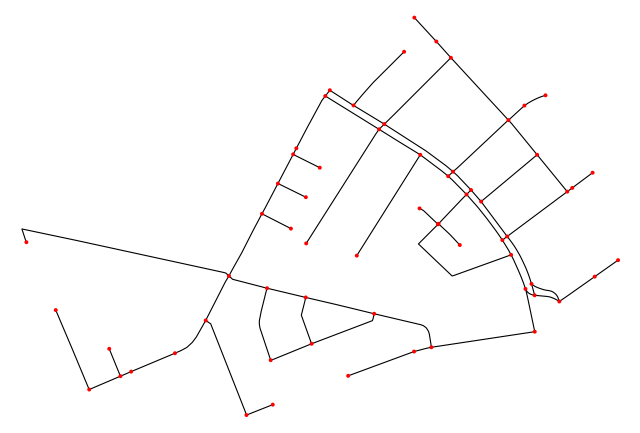

In [10]:
import osmnx as ox

ox.plot_graph(
        graphs[6],
        node_size=8,          # vertices visible
        node_color="red",
        edge_linewidth=0.8,   # edges visible
        edge_color="black",
        bgcolor="white",
        show=False,
        close=False,
    )

In [13]:
import networkx as nx

no_hole_indices = [
    i for i, G in enumerate(graphs)
    if nx.is_forest(G)
]

print("Graphs without holes (acyclic):", no_hole_indices)


Graphs without holes (acyclic): [65, 157, 196, 204, 277, 355]


In [14]:
import networkx as nx

graphs = [
    G for G in graphs
    if not nx.is_forest(G)
]


In [15]:
import numpy as np
kts = np.zeros((len(graphs), len(graphs)), dtype=float)

for i in range(len(graphs)):
    for j in range(len(graphs)):
        Q1 = compute_Q(graphs[i])
        Q2 = compute_Q(graphs[j])
        kts[i, j] = kttw(Q1, Q2, gamma=0.05)
        print(f"Kernel between graphs {i} and {j}: {kts[i, j]}")

Kernel between graphs 0 and 0: 1.0000000000000142
Kernel between graphs 0 and 1: 0.05395372850693535
Kernel between graphs 0 and 2: 0.0830207536720046
Kernel between graphs 0 and 3: 0.03745906778422297
Kernel between graphs 0 and 4: 0.2552874573376497
Kernel between graphs 0 and 5: 0.05900502318131675
Kernel between graphs 0 and 6: 0.07504123109443901
Kernel between graphs 0 and 7: 0.1123586072785799
Kernel between graphs 0 and 8: 0.08464096422619899
Kernel between graphs 0 and 9: 0.06203811291101298
Kernel between graphs 0 and 10: 0.07929214171896339
Kernel between graphs 0 and 11: 0.10036137355953696
Kernel between graphs 0 and 12: 0.08477753904243161
Kernel between graphs 0 and 13: 0.03139461339698123
Kernel between graphs 0 and 14: 0.07494705308889091
Kernel between graphs 0 and 15: 0.07411528386841094
Kernel between graphs 0 and 16: 0.08449407607272631
Kernel between graphs 0 and 17: 0.09190379573302751
Kernel between graphs 0 and 18: 0.0714377867889832
Kernel between graphs 0 and

In [48]:
import numpy as np

kts = np.asarray(kts)

rng = np.random.default_rng()

def sample_indices(mask, n=10):
    idx = np.argwhere(mask)
    if len(idx) == 0:
        return np.array([])
    n_sample = min(n, len(idx))
    chosen = rng.choice(len(idx), size=n_sample, replace=False)
    return idx[chosen]

# (0.9, 1)
idx_09_1_sample = sample_indices((kts > 0.9) & (kts < 1))

# (0.8, 0.9)
idx_08_09_sample = sample_indices((kts > 0.8) & (kts < 0.9))

# (0, 0.1)
idx_0_01_sample = sample_indices((kts > 0) & (kts < 0.1))

print("Indexes (0.9, 1):")
print(idx_09_1_sample)

print("\nIndexes (0.8, 0.9):")
print(idx_08_09_sample)

print("\nIndexes (0, 0.1):")
print(idx_0_01_sample)


Indexes (0.9, 1):
[[182 225]
 [ 68 206]
 [ 90  91]
 [226 226]
 [129 225]
 [ 98  98]
 [259  18]
 [242 162]
 [225 131]
 [130 250]]

Indexes (0.8, 0.9):
[[225 265]
 [ 65 174]
 [178 101]
 [137 249]
 [256 221]
 [249 272]
 [131  84]
 [101  84]
 [265  84]
 [219  44]]

Indexes (0, 0.1):
[[237 202]
 [189  75]
 [  9 199]
 [  6  92]
 [190  36]
 [ 31  34]
 [ 67 161]
 [ 71  66]
 [  6  18]
 [246  14]]


Creating a SVM to classify

In [59]:
import geopandas as gpd

# Load geojson directly
gdf = gpd.read_file("data/urban_patterns_clustered.geojson")
gdf["original_index"] = gdf.index

gdf_sorted = gdf.sort_values(
    by=["Shape_Area", "original_pattern"]
)


# Reset index (optional but recommended)
gdf_sorted = gdf_sorted.reset_index(drop=True)

gdf_sorted.head(10)


,Shape_Length,Shape_Area,geoid,state,county,tract,total_pop,male_under_5,male_5_to_9,male_10_to_14,...,b,c,abc,original_pattern,cluster,cluster_name,color_pattern,color_cluster,geometry,original_index
0,1157.946324,79458.396545,25025010408,25,025,010408,1280,4,16,8,...,0.137517,0.216288,100.0,gridiron,3,cul_de_sac,#0C850C,#F13F3F,"MULTIPOLYGON (((-71.09741 42.34369, -71.09651 ...",250
1,1584.372256,105649.372922,25025070901,25,025,070901,1268,0,31,26,...,0.544954,0.328440,100.0,organico,7,gridiron_bajo_street,#2399CF,#085d08,"MULTIPOLYGON (((-71.08181 42.33856, -71.08116 ...",209
2,1627.673122,106784.809746,25025030200,25,025,030200,1549,0,37,0,...,0.312121,0.248485,100.0,gridiron,7,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.05852 42.36695, -71.05835 ...",90
3,1371.495813,112148.566659,25025070801,25,025,070801,1148,30,0,0,...,0.581986,0.230947,100.0,gridiron,1,organico,#0C850C,#2399CF,"MULTIPOLYGON (((-71.08468 42.34029, -71.08431 ...",204
4,1635.410898,140715.695523,25025020302,25,025,020302,1201,31,37,14,...,0.335677,0.093146,100.0,gridiron,7,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.06516 42.3612, -71.0645 42...",261
5,1662.172503,141774.927594,25025030100,25,025,030100,2006,8,0,0,...,0.245783,0.177510,100.0,gridiron,7,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.05852 42.36695, -71.05807 ...",306
6,1744.670874,162207.251524,25025010403,25,025,010403,2580,0,31,29,...,0.269165,0.091993,100.0,gridiron,5,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.08985 42.34434, -71.08976 ...",159
7,2418.560054,197116.915259,25025070103,25,025,070103,647,5,17,9,...,0.187692,0.203077,100.0,cul_de_sac,3,cul_de_sac,#F13F3F,#F13F3F,"MULTIPOLYGON (((-71.06304 42.34685, -71.06301 ...",305
8,2192.485812,198467.006705,25025020200,25,025,020200,3124,65,37,27,...,0.214126,0.119955,100.0,gridiron,6,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.07237 42.36114, -71.07236 ...",161
9,1901.891211,203205.169735,25025070902,25,025,070902,2273,52,12,27,...,0.268293,0.491169,100.0,gridiron,6,gridiron_bajo_street,#0C850C,#085d08,"MULTIPOLYGON (((-71.08035 42.33936, -71.07964 ...",211


In [17]:
import json
import numpy as np

# Load the GeoJSON file
with open("data/urban_patterns_clustered.geojson", "r") as f:
    data = json.load(f)

# Extract 'original_pattern' as a NumPy array
original_pattern = np.array([
    feature["properties"]["original_pattern"]
    for feature in data["features"]
])


In [18]:
import numpy as np

indexes_to_remove = [65, 157, 196, 204, 277, 355]
original_pattern = np.delete(original_pattern, indexes_to_remove)

In [19]:
from sklearn.model_selection import train_test_split
G_train, G_test, y_train, y_test = train_test_split(graphs, original_pattern, test_size=0.2, random_state=50)


In [20]:
import numpy as np

n_train = len(G_train)
n_test = len(G_test)

kts = np.zeros((n_train, n_train), dtype=float)
kts_test = np.zeros((n_test, n_train), dtype=float)


In [21]:
for i in range(n_train):
    for j in range(n_train):
        Q1 = compute_Q(G_train[i])
        Q2 = compute_Q(G_train[j])
        kts[i, j] = kttw(Q1, Q2, gamma=0.1)

for i in range(n_test):
    for j in range(n_train):
        Q1 = compute_Q(G_test[i])
        Q2 = compute_Q(G_train[j])
        kts_test[i, j] = kttw(Q1, Q2, gamma=0.1)

In [23]:
from sklearn.svm import SVC
clf = SVC(kernel='precomputed')
clf.fit(kts, y_train)
SVC(kernel='precomputed')
y_pred = clf.predict(kts_test)

from sklearn.metrics import accuracy_score
print("%2.2f %%" %(round(accuracy_score(y_test, y_pred)*100)))

47.00 %


In [24]:
y_test

array(['gridiron', 'organico', 'cul_de_sac', 'organico', 'cul_de_sac',
       'gridiron', 'gridiron', 'gridiron', 'cul_de_sac', 'gridiron',
       'cul_de_sac', 'cul_de_sac', 'hibrido', 'gridiron', 'organico',
       'gridiron', 'gridiron', 'cul_de_sac', 'gridiron', 'gridiron',
       'hibrido', 'cul_de_sac', 'gridiron', 'gridiron', 'gridiron',
       'cul_de_sac', 'gridiron', 'gridiron', 'gridiron', 'gridiron',
       'organico', 'gridiron', 'cul_de_sac', 'organico', 'hibrido',
       'gridiron', 'hibrido', 'gridiron', 'gridiron', 'gridiron',
       'cul_de_sac', 'hibrido', 'hibrido', 'cul_de_sac', 'organico',
       'cul_de_sac', 'cul_de_sac', 'gridiron', 'gridiron', 'cul_de_sac',
       'organico', 'hibrido', 'gridiron', 'gridiron', 'cul_de_sac',
       'cul_de_sac', 'organico', 'gridiron', 'organico', 'cul_de_sac',
       'gridiron', 'hibrido', 'hibrido', 'gridiron', 'hibrido',
       'cul_de_sac', 'gridiron', 'cul_de_sac', 'gridiron', 'cul_de_sac'],
      dtype='<U10')

In [25]:
y_pred

array(['gridiron', 'gridiron', 'gridiron', 'organico', 'organico',
       'gridiron', 'gridiron', 'gridiron', 'cul_de_sac', 'gridiron',
       'gridiron', 'gridiron', 'organico', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'gridiron', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'gridiron', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'gridiron', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'organico', 'gridiron', 'gridiron',
       'gridiron', 'cul_de_sac', 'gridiron', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'organico', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'gridiron', 'gridiron', 'cul_de_sac',
       'gridiron', 'gridiron', 'gridiron', 'organico', 'gridiron',
       'gridiron', 'cul_de_sac', 'gridiron', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'organico', 'gridiron', 'gridiron',
       'gridiron', 'gridiron', 'gridiron', 'gridiron', 'gridiron'],
      dtype='<U10')

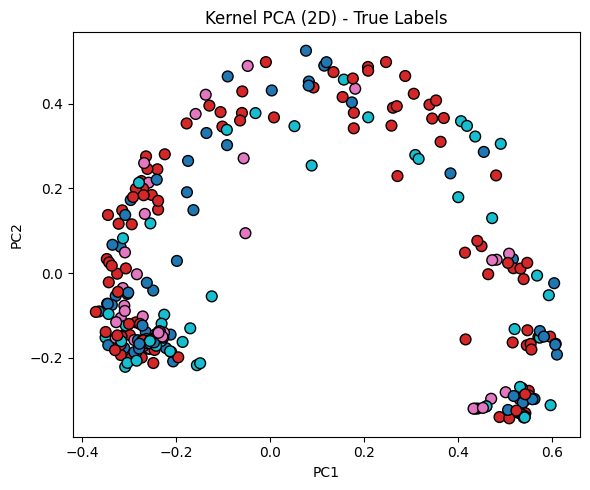

In [47]:
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y_train)

# 2D projection
kpca_vis = KernelPCA(n_components=2, kernel="precomputed", random_state=42)
X_train_2d = kpca_vis.fit_transform(kts)

fig, ax = plt.subplots(figsize=(6,5))

scatter = ax.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_encoded,
    cmap="tab10",   
    s=60,
    edgecolor="k"
)

ax.set_title("Kernel PCA (2D) - True Labels")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")


plt.tight_layout()
plt.show()
